# MLIPs and Mantid

<div style="background-color:#eaf1f9;border-left:5px solid #2b6cb0;border-radius:4px;padding:0.8em 1.2em;margin:0.6em 0;color:#1b1b1b">

**Objectives**

- Gain some basic experience using janus-core with MACE foundation models
- Perform geometry optimization and force constant calculations
- Simulate TOSCA spectrum using the Abins algorithm in Mantid Workbench (GUI)
- Simulate MARI spectrum using the Abins2D algorithm in Mantid Workbench (GUI)

</div>

## Running your first MLIP calculation with janus-core

A structure is provided for crystalline ethanol ([from COD](https://www.crystallography.net/cod/5910115.html)): you are encouraged to search for more and try them out! Just try to avoid really large cells or fractional occupations...

Janus-core uses ASE to import structures, so [most reasonable formats are supported](https://docs.ase-lib.org/ase/io/io.html).

In [4]:
import ase.io
from ase.visualize import view
atoms = ase.io.read("structures/ethanol.extxyz")
view(atoms, viewer='x3d')

We won't go into depth on ASE possibilities here: instead we will use the [janus-core](https://stfc.github.io/janus-core/) package which wraps up ASE and various MLIP interfaces into a set of command-line tools. As MLIPs are quite a fast-moving field, this saves us learning the different interfaces of each new MLIP package as it arrives. For this tutorial we will use MACE foundation models, which are quite smooth/stable for vibrational properties and transferable across a range of chemistries - but are on the expensive side for molecular dynamics.

In a Jupyter notebook, shell commands can be run in a block beginning with `%%bash`. You can follow along in the notebook or type the same commands in a terminal session. (Just make sure the Mantid conda environment is active!)

First we ask janus to calculate the energy of our ethanol structure using the MACE-OMAT-0 "small" model, which it will automatically download for us.

> The command is prefixed with "conda run -n ins-tutorial" so that it will work regardless of the environment the notebook software was launched from.
> If working from a command prompt, use `conda activate ins-tutorial` and then you can run `janus` commands directly.

In [7]:
%%bash
conda run -n ins-tutorial janus singlepoint --struct structures/ethanol.extxyz --arch mace_mp --model small

/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/e3nn/o3/_wigner.py:10: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  _Jd, _W3j_flat, _W3j_indices = torch.load(os.path.join(os.path.dirname(__file__), 'constants.pt'))
/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to 

cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
Using Materials Project MACE for MACECalculator with /Users/adam.jackson/.cache/mace/20231210mace128L0_energy_epoch249model
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.



(MACE does tend to create some pytorch deprecation warnings, don't worry about them too much.)

We should have created some files in `janus_results`: have a look at [ethanol-singlepoint-log.yml](./janus_results/ethanol-singlepoint-log.yml), [ethanol-singlepoint-results.extxyz](./janus_results/ethanol-singlepoint-results.extxyz) and [ethanol-singlepoint-summary.yml](./janus_results/ethanol-singlepoint-summary.yml).

<div style="background-color:#fdf2e4;border-left:5px solid #c05621;border-radius:4px;padding:0.8em 1.2em;margin:0.6em 0;color:#1b1b1b">

**Question**

- What does each file contain?
- What is the energy of this structure?
- Are the positions already optimized?

</div>

<div style="background-color:#e9f4ec;border-left:5px solid #2f7a4f;border-radius:4px;padding:0.8em 1.2em;margin:0.6em 0;color:#1b1b1b">

**Exploration**

Get a feel for how run-time scales with different systems and models.

- Try running another structure of interest from your own data.
- Try running the `medium` or `large` mace_mp models.

</div>

## Optimising the geometry

Phonon analysis requires low forces so we can sample the Hessian _at the stable geometry_. Ideally they would be exactly zero, but this is not always achievable.

To optimize the positions and lattice parameters with janus-core:

In [12]:
%%bash
conda run -n ins-tutorial janus geomopt --struct structures/ethanol.extxyz --arch mace_mp --model small --fmax 1e-5 --optimizer LBFGS --opt-cell-fully --fix-symmetry --write-traj

['cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.',
 'Using Materials Project MACE for MACECalculator with /Users/adam.jackson/.cache/mace/20231210mace128L0_energy_epoch249model',
 'Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.',
 '       Step     Time          Energy          fmax',
 'LBFGS:    0 10:29:24     -177.452082       19.189340',
 'LBFGS:    1 10:29:25     -185.144281        6.790467',
 'LBFGS:    2 10:29:25     -187.408267        4.516205',
 'LBFGS:    3 10:29:25     -188.645838        0.980332',
 'LBFGS:    4 10:29:25     -188.740789        0.591075',
 'LBFGS:    5 10:29:25     -188.861603        0.589409',
 'LBFGS:    6 10:29:25     -188.906737        0.404249',
 'LBFGS:    7 10:29:25     -188.928278        0.274583',
 'LBFGS:    8 10:29:25     -188.940675        0.248754',
 'LBFGS:    9 10:29:25     -188.952616        0.285083',
 'LBFGS:   10 10:29:26     -

<div style="background-color:#e9f4ec;border-left:5px solid #2f7a4f;border-radius:4px;padding:0.8em 1.2em;margin:0.6em 0;color:#1b1b1b">

**Tip**

- To explore the options for the geomopt command, use `janus geomopt --help`
- Running this with `conda -n run` suppresses the output until it is finished: for more interactive feedback try running in a shell after `conda activate ins-tutorial`.
</div>

For fun, we can convert the trajectory to a .gif file to view here. There are fancier jupyter-embeddable animation viewers but they don't seem to work directly on VISA :(

In [19]:
%%capture
traj = ase.io.read("janus_results/ethanol-traj.extxyz", index=":")
ase.io.write("ethanol-traj.gif", traj)

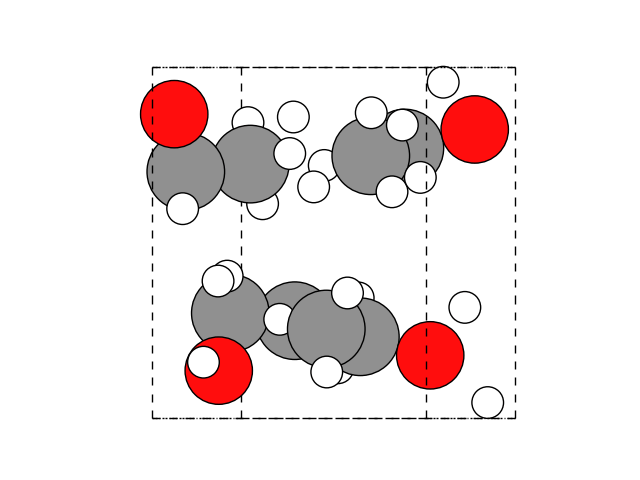

In [20]:
from IPython.display import Image
Image("ethanol-traj.gif")

For a richer exploration of the optimisation, use the virtual desktop and view the trajectory with `ase gui </path/to/ethanol-traj.extxyz>`.

<div style="background-color:#fdf2e4;border-left:5px solid #c05621;border-radius:4px;padding:0.8em 1.2em;margin:0.6em 0;color:#1b1b1b">

**Question**

- What does "LBFGS" mean?
- When _is_ it reasonable to achieve forces of exactly zero?
- MLIP studies can typically optimise structures to forces of ~1e-5 eV/Å, whereas phonon studies with density-functional theory (DFT) usually stop optimising around 1e-3 eV/Å. What is the limiting factor in each case?

</div>

## Calculating force constants

From the optimised structure, we are ready to do a phonon calculation. `janus-core` orchestrates ASE and Phonopy to get the force constant matrix by finite-displacements, using symmetry to reduce the required number of steps. We include a band structure plot for initial analysis.

In [26]:
%%bash
conda run -n ins-tutorial janus phonons --struct=janus_results/ethanol-opt.extxyz --arch=mace_mp --model=small --supercell='2 2 2' --bands --plot-to-file

cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
Using Materials Project MACE for MACECalculator with /Users/adam.jackson/.cache/mace/20231210mace128L0_energy_epoch249model
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.

Computing displacements... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   0/108 -:--:--
Computing displacements... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   1/108 -:--:--
Computing displacements... ╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   2/108 0:01:21
Computing displacements... ━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   3/108 0:01:11
Computing displacements... ━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   4/108 0:01:06
Computing displacements... ━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   5/108 0:01:03
Computing displacements... ━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   6/108 0:01:01
Computing displacements... ━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   7/108 0:01:00
Computing displa

/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/e3nn/o3/_wigner.py:10: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  _Jd, _W3j_flat, _W3j_indices = torch.load(os.path.join(os.path.dirname(__file__), 'constants.pt'))
/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to 

Have a look at the resulting phonon band structure plot (also known as a phonon dispersion plot), *ethanol-opt-bands.svg*. The x-axis labels represent high-symmetry points in reciprocal space: the Bilbao Crystallographic Server provides [useful tools](https://cryst.ehu.es/cryst/get_kvec.html) to explore these further.

<div style="background-color:#fdf2e4;border-left:5px solid #c05621;border-radius:4px;padding:0.8em 1.2em;margin:0.6em 0;color:#1b1b1b">

**Question**
- Does this phonon dispersion plot indicate a stable geometry?
- How does the calculation cost scale with `supercell` options? How would it scale for DFT?
- When _is_ it reasonable to achieve forces of exactly zero?
- MLIP studies can typically optimise structures to forces of ~1e-5 eV/Å, whereas phonon studies with density-functional theory (DFT) usually stop optimising around 1e-3 eV/Å. What is the limiting factor in each case?

</div>

## Simulating a molecular spectroscopy experiment using the "Abins" algorithms in Mantid

From a virtual desktop, launch Mantid workbench with

```
conda run -n mantid workbench
```

![Mantid opening](images/mantid-start.jpg)

On the splash screen, click "Manage User Directories" and set the Default Save Directory to somewhere writeable such as your Desktop. (If you missed the splash screen, this can also be done from the File menu.)

Mantid is primarily used for experimental data reduction and analysis, but also contains some useful simulation routines. In the bottom-left of the interface is the list of "Algorithms", find Abins in the "Simulation" section and double-click to open the dialogue.

![find-abins](images/find-abins.jpg)

For VibrationalOrPhononFile, select the filename ending with `phonopy.yml` and for AbInitioProgram choose FORCECONSTANTS. This directs Abins to sample an automatic **q**-points mesh by Fourier interpolation from the force-constants data. The input file must either contain force constants or be a `phonopy.yml` with a corresponding force_constants.hdf5 file sitting in the same directory. For the other parameters, follow the screenshop below and "Run".

![abins-settings](images/abins-settings.jpg)

This should take a few seconds to run and create "workspaces" in the left-hand pane. To plot the results: unfold the workspace group, right-click the desired spectrum (or spectra) and navigate to Plot -> Spectrum...

![plot-1d](images/mantid-1d-plot.jpg)

The resulting plot should resemble an experimental spectrum: multi-phonon contributions have been computed and instrumental resolution effects included.

![ethanol-tosca-sim](images/ethanol-tosca-sim.jpg)

<div style="background-color:#fdf2e4;border-left:5px solid #c05621;border-radius:4px;padding:0.8em 1.2em;margin:0.6em 0;color:#1b1b1b">

**Questions**

Have a look at the historical measurement for ethanol in the [ISIS INS Database](http://wwwisis2.isis.rl.ac.uk/INSdatabase/) and consider the main differences with this simulated spectrum.
- Which of these might be attributed to the quality of MLIP?
- Which of these are likely due to the difference in instrumentation? (TXFA is a predecessor to TOSCA.)
- Which of these are likely due to the modelling approach?

</div>

## Simulating a 2-D spectrum with Abins2D

Direct-geometry spectrometers such as MAPS and MARI have space for detectors at many scattering angles, allowing collection over a significant volume of $\mathbf{q},\omega)$ space. For liquid-phase or powder samples the direction of **q** is uninteresting and the data is generally presented as a 2--D $S(Q, \omega)$ map.

To compute this using similar approximations to the 1-D powder-averaging Abins algorithm, use the Abins2D algorithm with options as shown.

![mari-settings](images/mari-settings.jpg)

The resulting spectrum can be given a simple 2-D plot with the "Colorfill" menu option.

![find-colorfill](images/find-colorfill.jpg)

But for an interesting interactive exploration of energy and Q projections try the "Slice Viewer".

![slice-viewer](images/slice-viewer.jpg)

<div style="background-color:#fdf2e4;border-left:5px solid #c05621;border-radius:4px;padding:0.8em 1.2em;margin:0.6em 0;color:#1b1b1b">

**Questions**
- Why do peaks at different energies have their maxima at different Q values?
- Is there a trend?

</div>

<div style="background-color:#e9f4ec;border-left:5px solid #2f7a4f;border-radius:4px;padding:0.8em 1.2em;margin:0.6em 0;color:#1b1b1b">

**Exploration**

Try different incident energies, instruments and chopper settings. Pay attention to how they affect the instrument resolution.

</div>